In [1]:
import gzip
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# defining a function that will load MNIST images
def load_images(path):
    with gzip.open(path, "rb") as f:
        data = f.read() # reads and adds to a variable the whole un-gzipped file as raw bytes

    pixels = np.frombuffer(data, dtype=np.uint8, offset=16) # focusing on everything after the 16-byte header
    images = pixels.reshape(-1, 784) # converts the 1D vector of pixels into a matrix, where each row represents an image and each column represents one pixel out of a 28x28 image
    return images

In [3]:
# defining a function that will load MNIST image labels
def load_labels(path):
    with gzip.open(path, "rb") as f:
        data = f.read() # reads and adds to a variable the whole un-gzipped file as raw bytes

    labels = np.frombuffer(data, dtype=np.uint8, offset=8) # focusing on everything after the 8-byte header
    return labels

# Load MNIST:

In [4]:
X_train_raw = load_images("../data/mnist/train-images-idx3-ubyte.gz")
y_train_raw = load_labels("../data/mnist/train-labels-idx1-ubyte.gz")
X_test_raw  = load_images("../data/mnist/t10k-images-idx3-ubyte.gz")
y_test_raw  = load_labels("../data/mnist/t10k-labels-idx1-ubyte.gz")
print(X_train_raw.shape, y_train_raw.shape, X_test_raw.shape, y_test_raw.shape)
print(y_train_raw[:10])

(60000, 784) (60000,) (10000, 784) (10000,)
[5 0 4 1 9 2 1 3 1 4]


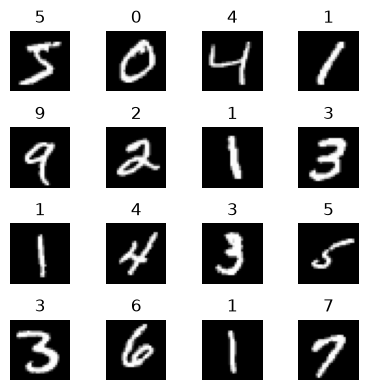

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(4,4))
for i in range(16):
    ax = axes.flat[i]
    ax.imshow(X_train_raw[i].reshape(28, 28), cmap="gray")
    ax.set_title(y_train_raw[i])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
class_proportions = np.bincount(y_train_raw) / len(y_train_raw)
np.round(class_proportions*100, 2) # each digit makes up ~9-11% of the training data set

array([ 9.87, 11.24,  9.93, 10.22,  9.74,  9.04,  9.86, 10.44,  9.75,
        9.92])

# Class Proportions and Majority-Class Baseline:

MNIST classes are *balanced*, i.e. each digit makes up roughly the same number of images in the whole training set.

The most common digit in MNIST is 1 with ~11% occurrence rate.

Therefore, if a "model" always guessed that a given digit was the digit with the greatest occurrence rate (1), then the accuracy would be ~11%.

This is the **"majority-class baseline"**.

With imbalanced classes, accuracy alone can mislead, so always compare against the majority-class baseline.

A model that always guesses the number "1" no matter what, could have vastly different accuracy depending on how balanced the dataset is that it's classifying digits from.

In [7]:
X_train_full = X_train_raw.astype("float32")/255 # converts each pixel to float32 and makes each one a value 0-1
X_test_full = X_test_raw.astype("float32")/255
print(X_train_full.dtype, X_train_full.min(), X_train_full.max())

y_train_full = y_train_raw
y_test_full = y_test_raw

float32 0.0 1.0


In [9]:
X_train = X_train_full[:50000]
X_val = X_train_full[50000:] # splitting into 50,000 training images and 10,000 validation images
y_train = y_train_full[:50000]
y_val = y_train_full[50000:] # doing the same for the respective labels

print(X_train.shape, y_train.shape, X_val.shape, y_val.shape)

print(y_train[:10])

(50000, 784) (50000,) (10000, 784) (10000,)
[5 0 4 1 9 2 1 3 1 4]
